# 2. Analyse der Fragen mit fester Antwort

Erstellt Diagramme für Likert-, Single-Choice- und Multiple-Choice-Fragen und speichert sie in `outputs/figures/`.

In [6]:
import sys
from pathlib import Path

import pandas as pd

sys.path.append(str(Path.cwd().parent))
from src.utils import plot_single_choice, plot_likert, plot_yes_no_multi_select, save_figure

PROCESSED_PATH = Path("../data/processed/survey_clean.csv")
df = pd.read_csv(PROCESSED_PATH)

cols = df.columns
education = cols[5]
years_coding_total = cols[6]
learned_ai_at_work = cols[19]
job_role = cols[20]
years_experience = cols[21]
languages_used = cols[22]
uses_ai_tools = cols[23]
ai_stance = cols[24]
ai_threat = cols[25]
process_flexibility = cols[52]
similar_or_different = cols[54]

learn_to_code_columns = cols[7:19].tolist()
nonfunctional_req_columns = cols[26:34].tolist()
constraint_columns = cols[34:52:2].tolist()

df.head()

,Response ID,Date submitted,Last page,Start language,Seed,Which of the following best describes the highest level of formal education that you've completed?,"Including any education, how many years have you been coding in total? Please round to the nearest whole number, excluding any decimal points.",How did you learn to code in the past year? [Technical documentation (is generated for/by the tool or system],"How did you learn to code in the past year? [Other online resources (e.g. standard search, forum, online community]",How did you learn to code in the past year? [Stack Overflow or Stack Exchange],...,Which projects or operational constraints have the greatest influence on software development decisions in your field of work? Please briefly explain why the selected constraints have a particularly strong influence on software development decisions in your field of work. [Legacy systems][Comment],Which projects or operational constraints have the greatest influence on software development decisions in your field of work? Please briefly explain why the selected constraints have a particularly strong influence on software development decisions in your field of work. [Organizational constraints],Which projects or operational constraints have the greatest influence on software development decisions in your field of work? Please briefly explain why the selected constraints have a particularly strong influence on software development decisions in your field of work. [Organizational constraints][Comment],Which projects or operational constraints have the greatest influence on software development decisions in your field of work? Please briefly explain why the selected constraints have a particularly strong influence on software development decisions in your field of work. [I don't know],Which projects or operational constraints have the greatest influence on software development decisions in your field of work? Please briefly explain why the selected constraints have a particularly strong influence on software development decisions in your field of work. [I don't know][Comment],To what extent can development teams in your field of work choose or adapt the software development process they use?,Which factors have the greatest influence on the choice or adaption of the software development process?,"In your opinion, will software engineering in the space sector and software engineering in other domains become more similar or more different in the future? Please briefly explain the reason for your answer.","In your opinion, will software engineering in the space sector and software engineering in other domains become more similar or more different in the future? Please briefly explain the reason for your answer. [Comment]",Is there anything else you would like to share that is relevant to this topic?
0,5,1980-01-01 00:00:00,4.0,en,238307838,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",6 to 10 years,No,Yes,Yes,...,NaN,No,NaN,No,NaN,High flexibility,NaN,NaN,NaN,NaN
1,9,1980-01-01 00:00:00,4.0,en,193893040,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",16 to 20 years,Yes,Yes,Yes,...,This goes together with the long mission lifet...,No,NaN,No,NaN,Moderate flexibility,- ECSS standards\n- Previous experience of the...,Become somewhat more similar,More standardized platforms/interfaces,NaN
2,10,1980-01-01 00:00:00,4.0,en,1433496783,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",11 to 15 years,Yes,Yes,Yes,...,NaN,No,NaN,No,NaN,High flexibility,NaN,Remain approximately as they are today,NaN,NaN
3,11,1980-01-01 00:00:00,4.0,en,1373684769,"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",41 to 50 years,Yes,Yes,Yes,...,NaN,Yes,Fullfilment of ECSS requirements,No,NaN,Limited flexibility,Acceptance by the customers (ESA or NASA stand...,Become much more different,There is a big difference between the domains....,NaN
4,12,1980-01-01 00:00:00,4.0,en,1914825945,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",6 to 10 years,Yes,No,Yes,...,Na

## Fragen mit fester (ordinaler) Reihenfolge

WindowsPath('C:/Users/andre/OneDrive - Chemische Werke Kluthe GmbH/Dokumente/Vorlesungen 8tes Semester/Bachelorarbeit/Analysis Survey/outputs/figures/years_experience.png')

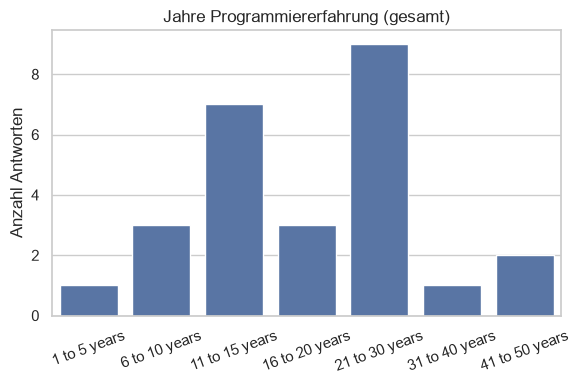

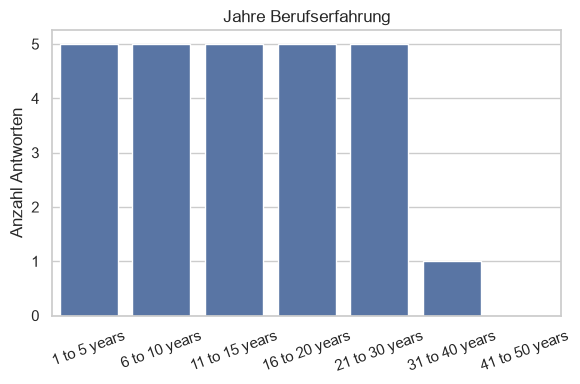

In [5]:
experience_order = ["1 to 5 years", "6 to 10 years", "11 to 15 years", "16 to 20 years",
                     "21 to 30 years", "31 to 40 years", "41 to 50 years"]

fig = plot_likert(df, column=years_coding_total, order=experience_order, title="Jahre Programmiererfahrung (gesamt)")
save_figure(fig, "years_coding_total")

fig = plot_likert(df, column=years_experience, order=experience_order, title="Jahre Berufserfahrung")
save_figure(fig, "years_experience")

WindowsPath('C:/Users/andre/OneDrive - Chemische Werke Kluthe GmbH/Dokumente/Vorlesungen 8tes Semester/Bachelorarbeit/Analysis Survey/outputs/figures/similar_or_different.png')

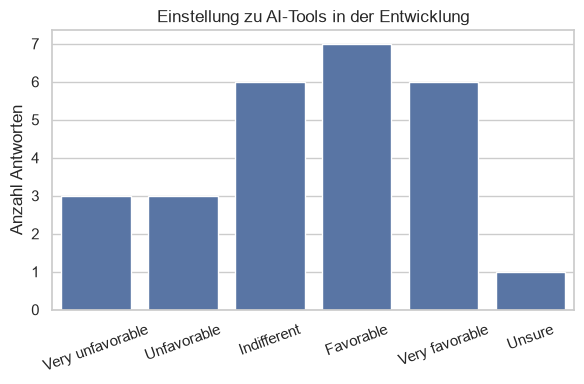

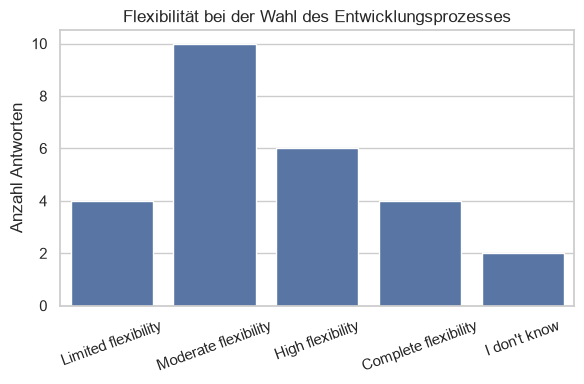

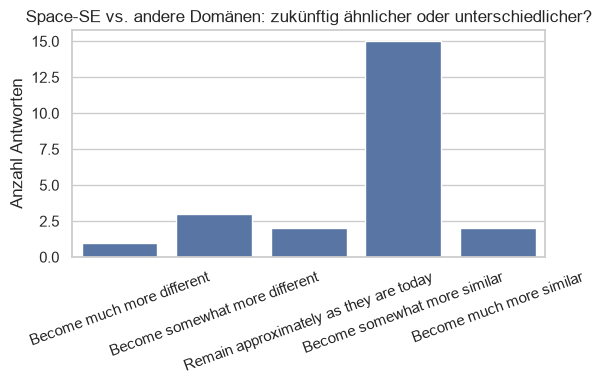

In [7]:
ai_stance_order = ["Very unfavorable", "Unfavorable", "Indifferent", "Favorable", "Very favorable", "Unsure"]
fig = plot_likert(df, column=ai_stance, order=ai_stance_order, title="Einstellung zu AI-Tools in der Entwicklung")
save_figure(fig, "ai_stance")

flexibility_order = ["Limited flexibility", "Moderate flexibility", "High flexibility",
                      "Complete flexibility", "I don't know"]
fig = plot_likert(df, column=process_flexibility, order=flexibility_order, title="Flexibilität bei der Wahl des Entwicklungsprozesses")
save_figure(fig, "process_flexibility")

similarity_order = ["Become much more different", "Become somewhat more different",
                     "Remain approximately as they are today", "Become somewhat more similar",
                     "Become much more similar"]
fig = plot_likert(df, column=similar_or_different, order=similarity_order, title="Space-SE vs. andere Domänen: zukünftig ähnlicher oder unterschiedlicher?")
save_figure(fig, "similar_or_different")

## Single-Choice-Fragen (nominal, ohne feste Reihenfolge)

WindowsPath('C:/Users/andre/OneDrive - Chemische Werke Kluthe GmbH/Dokumente/Vorlesungen 8tes Semester/Bachelorarbeit/Analysis Survey/outputs/figures/learned_ai_at_work.png')

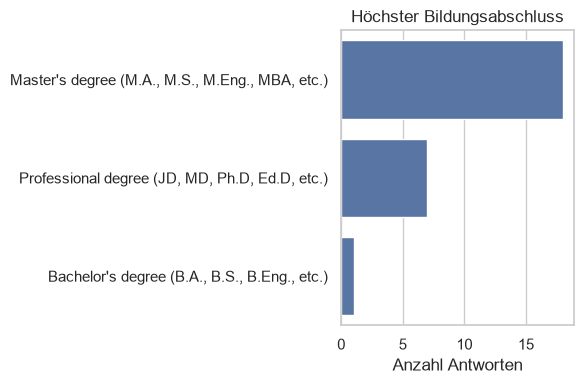

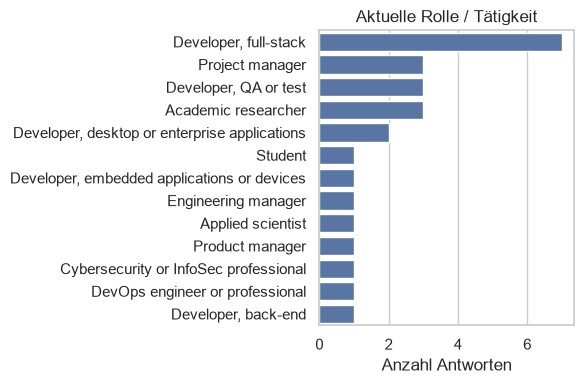

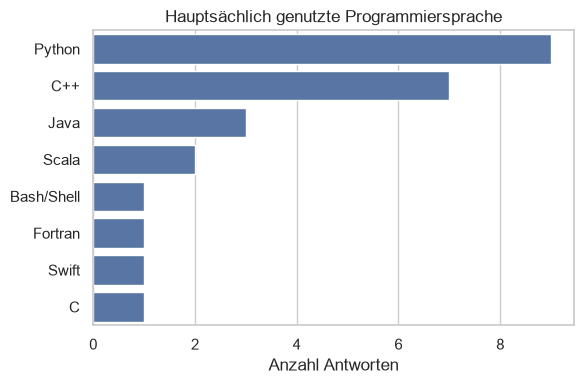

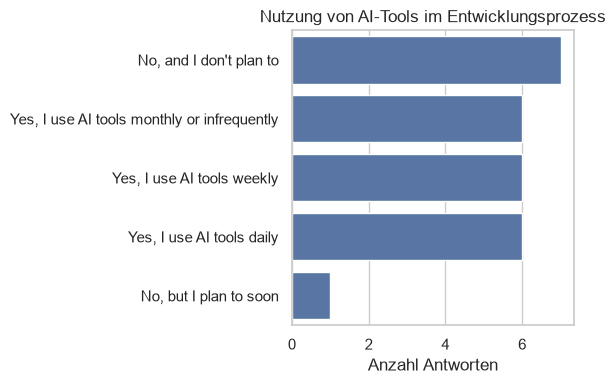

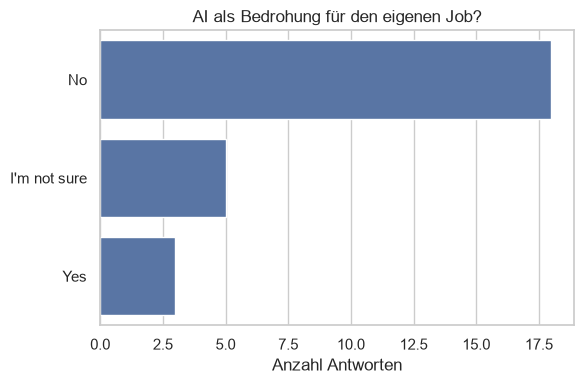

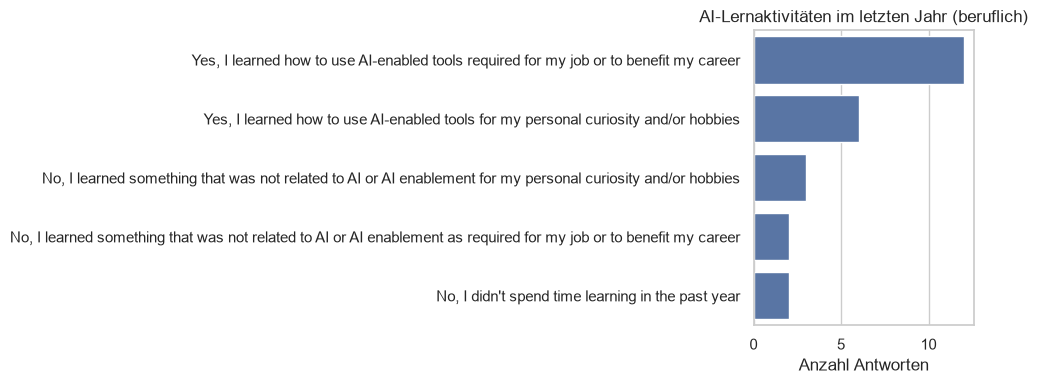

In [9]:
fig = plot_single_choice(df, column=education, title="Höchster Bildungsabschluss")
save_figure(fig, "education")

fig = plot_single_choice(df, column=job_role, title="Aktuelle Rolle / Tätigkeit")
save_figure(fig, "job_role")

fig = plot_single_choice(df, column=languages_used, title="Hauptsächlich genutzte Programmiersprache")
save_figure(fig, "languages_used")

fig = plot_single_choice(df, column=uses_ai_tools, title="Nutzung von AI-Tools im Entwicklungsprozess")
save_figure(fig, "uses_ai_tools")

fig = plot_single_choice(df, column=ai_threat, title="AI als Bedrohung für den eigenen Job?")
save_figure(fig, "ai_threat")

fig = plot_single_choice(df, column=learned_ai_at_work, title="AI-Lernaktivitäten im letzten Jahr (beruflich)", figsize=(10, 4))
save_figure(fig, "learned_ai_at_work")

## Multiple-Choice-Fragen

WindowsPath('C:/Users/andre/OneDrive - Chemische Werke Kluthe GmbH/Dokumente/Vorlesungen 8tes Semester/Bachelorarbeit/Analysis Survey/outputs/figures/operational_constraints.png')

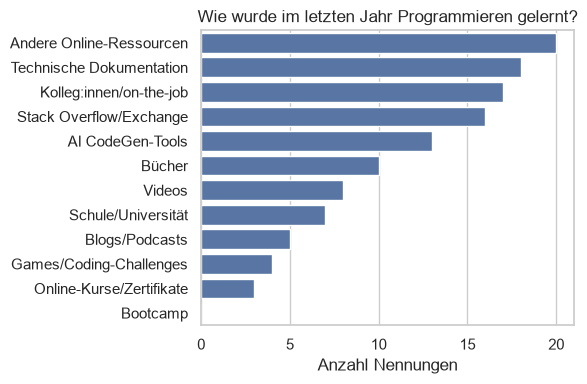

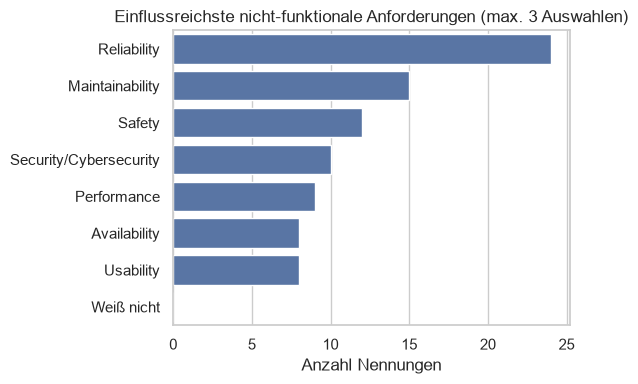

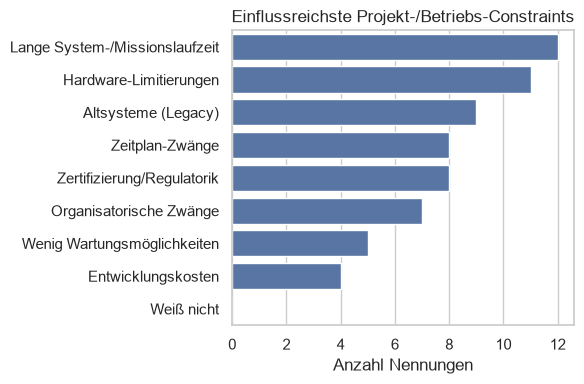

In [4]:
learn_to_code_labels = [
    "Technische Dokumentation", "Andere Online-Ressourcen", "Stack Overflow/Exchange",
    "Videos", "AI CodeGen-Tools", "Blogs/Podcasts", "Online-Kurse/Zertifikate",
    "Bücher", "Kolleg:innen/on-the-job", "Schule/Universität", "Games/Coding-Challenges", "Bootcamp",
]
fig = plot_yes_no_multi_select(df, learn_to_code_columns, labels=learn_to_code_labels,
                                title="Wie wurde im letzten Jahr Programmieren gelernt?")
save_figure(fig, "learn_to_code")

nonfunctional_req_labels = [
    "Reliability", "Safety", "Security/Cybersecurity", "Performance",
    "Maintainability", "Availability", "Usability", "Weiß nicht",
]
fig = plot_yes_no_multi_select(df, nonfunctional_req_columns, labels=nonfunctional_req_labels,
                                title="Einflussreichste nicht-funktionale Anforderungen (max. 3 Auswahlen)")
save_figure(fig, "nonfunctional_requirements")

constraint_labels = [
    "Hardware-Limitierungen", "Lange System-/Missionslaufzeit", "Wenig Wartungsmöglichkeiten",
    "Zertifizierung/Regulatorik", "Entwicklungskosten", "Zeitplan-Zwänge",
    "Altsysteme (Legacy)", "Organisatorische Zwänge", "Weiß nicht",
]
fig = plot_yes_no_multi_select(df, constraint_columns, labels=constraint_labels,
                                title="Einflussreichste Projekt-/Betriebs-Constraints")
save_figure(fig, "operational_constraints")